# Sprint 4 — Arquitetura GPT e Geração Autoregressiva
**Disciplina:** Inteligência Artificial — Unoesc  
**Referência Principal:** *Build a Large Language Model (From Scratch)* — Capítulo 4 (Sebastian Raschka)  

---

## 🎯 Objetivos da Sprint
1. Integrar os blocos de atenção desenvolvidos na Sprint 3 aos componentes do Transformer.
2. Implementar **Layer Normalization**, ativação **GELU**, rede **FeedForward** e **TransformerBlock** com conexões residuais Pre-LayerNorm.
3. Construir a arquitetura completa do **GPTModel** (Embeddings de tokens e posições, empilhamento de blocos, normalização final e Language Model Head).
4. Implementar e comparar algoritmos de **Geração Autoregressiva**: busca gananciosa (*greedy*), escalonamento por **Temperatura** e amostragem com **Top-K**.
5. Realizar experimentos empíricos sobre a alocação de parâmetros, estabilidade de ativações e dinâmicas de amostragem.


In [1]:
import os
import sys
from pathlib import Path
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

# Adiciona o diretório raiz ao sys.path para importação dos módulos de src
repo_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.atencao import MultiHeadAttention
from src.modelo_gpt import (
    LayerNorm, GELU, FeedForward, TransformerBlock, GPTModel,
    generate_text_simple, generate_text_advanced,
    GPT_CONFIG_124M, GPT_CONFIG_TESTE
)

# Configurações visuais e semente de reprodutibilidade
torch.manual_seed(123)
np.random.seed(123)
os.makedirs(repo_root / 'experimentos', exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print("Ambiente e módulos importados com sucesso!")
print(f"Dispositivo PyTorch: {'cuda' if torch.cuda.is_available() else 'cpu'}")
print(f"Versão do PyTorch: {torch.__version__}")


Ambiente e módulos importados com sucesso!
Dispositivo PyTorch: cuda
Versão do PyTorch: 2.13.0+cu130


## 1. Módulos Estruturais Fundamentais do Transformer

Nesta seção, exploramos os componentes internos que formam o **Transformer Block**:
* **LayerNorm:** Normaliza as ativações de cada amostra individualmente através da dimensão de características ($d_{model}$), mantendo média 0 e variância 1 com parâmetros treináveis $\gamma$ (escala) e $\beta$ (deslocamento).
* **GELU (Gaussian Error Linear Unit):** Ativação suave não linear que pondera as entradas pela função de distribuição cumulativa da distribuição normal, evitando o problema de gradiente nulo da ReLU tradicional.
* **FeedForward Network (FFN):** Expande a representação latente ($d_{model} \to 4 \times d_{model}$), aplica GELU e projeta de volta para $d_{model}$ com Dropout.
* **TransformerBlock:** Combina a atenção causal multi-cabeça e a rede FeedForward sob a arquitetura **Pre-LayerNorm**, somando conexões residuais (*skip connections*).


[LayerNorm] Entrada: torch.Size([2, 6, 64]) -> Saída: torch.Size([2, 6, 64])
[LayerNorm] Média após normalização: -0.00000 (esperado ~0.0)
[LayerNorm] Variância após normalização: 1.00129 (esperado ~1.0)


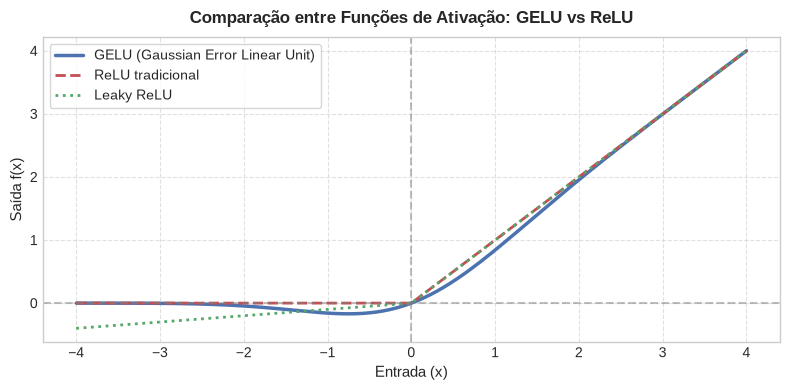

[TransformerBlock] Entrada: torch.Size([2, 6, 64]) -> Saída: torch.Size([2, 6, 64])


In [2]:
# Demonstração e Validação dos Módulos Individuais
batch_size = 2
seq_len = 6
emb_dim = 64
x_exemplo = torch.randn(batch_size, seq_len, emb_dim)

# 1. Teste de Layer Normalization
ln = LayerNorm(emb_dim=emb_dim)
x_norm = ln(x_exemplo)
print(f"[LayerNorm] Entrada: {x_exemplo.shape} -> Saída: {x_norm.shape}")
print(f"[LayerNorm] Média após normalização: {x_norm.mean().item():.5f} (esperado ~0.0)")
print(f"[LayerNorm] Variância após normalização: {x_norm.var().item():.5f} (esperado ~1.0)")

# 2. Comparativo Visual: GELU vs ReLU vs LeakyReLU
x_vals = torch.linspace(-4, 4, 200)
gelu_custom = GELU()
y_gelu = gelu_custom(x_vals).numpy()
y_relu = torch.relu(x_vals).numpy()
y_lrelu = torch.nn.functional.leaky_relu(x_vals, negative_slope=0.1).numpy()

plt.figure(figsize=(8, 4))
plt.plot(x_vals.numpy(), y_gelu, label='GELU (Gaussian Error Linear Unit)', color='#4C72B0', linewidth=2.5)
plt.plot(x_vals.numpy(), y_relu, '--', label='ReLU tradicional', color='#C44E52', linewidth=2)
plt.plot(x_vals.numpy(), y_lrelu, ':', label='Leaky ReLU', color='#55A868', linewidth=2)
plt.title('Comparação entre Funções de Ativação: GELU vs ReLU', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Entrada (x)', fontsize=11)
plt.ylabel('Saída f(x)', fontsize=11)
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(0, color='gray', linestyle='--', alpha=0.5)
plt.legend(frameon=True, facecolor='white')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Teste do TransformerBlock Completo
cfg_bloco = {
    "emb_dim": emb_dim,
    "context_length": 32,
    "n_heads": 4,
    "drop_rate": 0.1,
    "qkv_bias": False
}
bloco = TransformerBlock(cfg_bloco)
out_bloco = bloco(x_exemplo)
print(f"[TransformerBlock] Entrada: {x_exemplo.shape} -> Saída: {out_bloco.shape}")
assert out_bloco.shape == x_exemplo.shape, "O formato do tensor deve ser preservado pelo bloco Transformer!"


## 2. Construção do Modelo GPT (`GPTModel`)

O modelo completo integra:
1. **Token Embeddings:** Mapeia cada token ID para um vetor denso em $\mathbb{R}^{d_{model}}$.
2. **Positional Embeddings:** Injeta informação ordinal sobre a posição de cada token na sequência ($0, 1, \dots, T-1$).
3. **Dropout:** Regularização inicial aplicada à soma dos embeddings.
4. **Pilha de $N$ Blocos Transformer:** Processamento e refinamento progressivo das representações contextuais.
5. **Normalização Final:** Aplicação de `LayerNorm` sobre as saídas do último bloco.
6. **Language Model Head (LM Head):** Camada linear projetando de $d_{model}$ para o tamanho do vocabulário ($V$), gerando os **Logits** brutos para cada posição.


In [3]:
# Instanciação da Arquitetura GPT
cfg_teste = {
    "vocab_size": 1000,
    "context_length": 64,
    "emb_dim": 128,
    "n_heads": 4,
    "n_layers": 4,
    "drop_rate": 0.1,
    "qkv_bias": False
}

modelo_teste = GPTModel(cfg_teste)
modelo_teste.eval()

# Entrada simulada de Token IDs
tokens_entrada = torch.randint(0, cfg_teste["vocab_size"], (batch_size, 8))
with torch.no_grad():
    logits_saida = modelo_teste(tokens_entrada)

print(f"Tensor de entrada (Token IDs): {tokens_entrada.shape} -> (batch_size, seq_len)")
print(f"Tensor de saída (Logits):      {logits_saida.shape} -> (batch_size, seq_len, vocab_size)")

# Contagem detalhada de parâmetros
n_params = sum(p.numel() for p in modelo_teste.parameters())
print(f"Total de parâmetros do modelo de teste: {n_params:,}")


Tensor de entrada (Token IDs): torch.Size([2, 8]) -> (batch_size, seq_len)
Tensor de saída (Logits):      torch.Size([2, 8, 1000]) -> (batch_size, seq_len, vocab_size)
Total de parâmetros do modelo de teste: 1,056,000


## 3. Inferência e Geração Autoregressiva de Texto

A geração autoregressiva ocorre de forma sequencial iterativa:
1. O modelo recebe o contexto atual de tokens: $[t_1, t_2, \dots, t_k]$.
2. Se a sequência exceder `context_length`, ela é truncada para os últimos `context_length` tokens.
3. A passagem para frente (*forward pass*) produz logits para todas as posições; selecionam-se os logits da **última posição** ($t_k$).
4. Estratégias de amostragem:
   * **Busca Gananciosa (*Greedy*):** Seleção determinística do token com o maior valor de logit (argmax).
   * **Escalonamento por Temperatura ($T$):** Ajusta a aleatoriedade da distribuição Softmax ($z_i / T$).
   * **Truncamento Top-K:** Restringe o sorteio apenas aos $K$ tokens mais prováveis, zerando os demais com $-\infty$.
5. O novo token previsto é concatenado ao contexto, repetindo-se o ciclo até atingir `max_new_tokens`.


In [4]:
# Testando os Modos de Geração Autoregressiva
prompt_tokens = torch.tensor([[10, 45, 88, 302]])  # Prompt de 4 tokens
max_tokens_gerados = 12

# 1. Geração Gananciosa (Greedy)
saida_greedy = generate_text_simple(
    model=modelo_teste,
    idx=prompt_tokens.clone(),
    max_new_tokens=max_tokens_gerados,
    context_size=cfg_teste["context_length"]
)
print(f"Prompt inicial:  {prompt_tokens.tolist()[0]}")
print(f"Saída Greedy:    {saida_greedy.tolist()[0]}")

# 2. Geração Avançada com Temperatura Baixa (T=0.3, previsível)
saida_temp_baixa = generate_text_advanced(
    model=modelo_teste,
    idx=prompt_tokens.clone(),
    max_new_tokens=max_tokens_gerados,
    context_size=cfg_teste["context_length"],
    temperature=0.3,
    top_k=10
)
print(f"Saída (T=0.3, Top-K=10): {saida_temp_baixa.tolist()[0]}")

# 3. Geração Avançada com Temperatura Alta (T=1.5, criativa/estocástica)
saida_temp_alta = generate_text_advanced(
    model=modelo_teste,
    idx=prompt_tokens.clone(),
    max_new_tokens=max_tokens_gerados,
    context_size=cfg_teste["context_length"],
    temperature=1.5,
    top_k=10
)
print(f"Saída (T=1.5, Top-K=10): {saida_temp_alta.tolist()[0]}")


Prompt inicial:  [10, 45, 88, 302]
Saída Greedy:    [10, 45, 88, 302, 248, 46, 985, 708, 748, 585, 942, 463, 454, 821, 784, 737]
Saída (T=0.3, Top-K=10): [10, 45, 88, 302, 78, 270, 176, 391, 920, 248, 836, 333, 877, 560, 100, 892]
Saída (T=1.5, Top-K=10): [10, 45, 88, 302, 774, 810, 832, 786, 762, 482, 978, 255, 458, 274, 448, 731]


## 4. Experimentos e Análise Empírica da Sprint 4

Nesta seção, executamos os três experimentos formais da Sprint 4:
* **Experimento 4.1:** Alocação Arquitetural e Contagem de Parâmetros em Diferentes Escalas.
* **Experimento 4.2:** Estabilidade das Ativações: Pre-LayerNorm vs Sem Normalização.
* **Experimento 4.3:** Dinâmica da Distribuição Softmax: Efeito da Temperatura e Truncamento Top-K.


Mini (4L, 128D)    | Total:   3.38M | Emb:  1.31M | Blocos:  0.79M | Head:  1.28M


Médio (8L, 384D)   | Total:  33.58M | Emb:  9.80M | Blocos: 14.19M | Head:  9.60M


GPT-2 124M         | Total: 163.01M | Emb: 39.38M | Blocos: 85.03M | Head: 38.60M


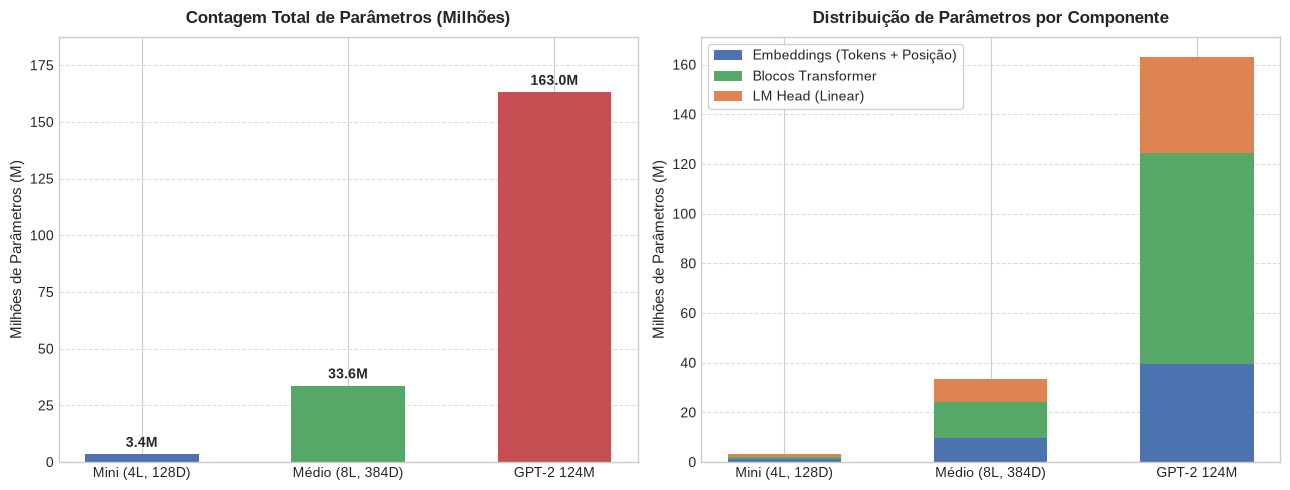

Figura salva em: /home/msoph/Documentos/0-Docs/Cursed-2026/Unoesc/IA/INTELIGENCIA-ARTIFICIAL-434302/experimentos/grafico_parametros_sprint4.png


In [5]:
# ==============================================================================
# Experimento 4.1: Alocação Arquitetural e Escala de Parâmetros
# ==============================================================================
modelos_config = {
    'Mini (4L, 128D)': {'vocab_size': 10000, 'context_length': 256, 'emb_dim': 128, 'n_heads': 4, 'n_layers': 4, 'drop_rate': 0.1, 'qkv_bias': False},
    'Médio (8L, 384D)': {'vocab_size': 25000, 'context_length': 512, 'emb_dim': 384, 'n_heads': 6, 'n_layers': 8, 'drop_rate': 0.1, 'qkv_bias': False},
    'GPT-2 124M': GPT_CONFIG_124M
}

nomes_modelos = list(modelos_config.keys())
params_emb, params_blocos, params_head, params_totais = [], [], [], []

for nome, c in modelos_config.items():
    m = GPTModel(c)
    total_p = sum(p.numel() for p in m.parameters())
    e_p = sum(p.numel() for p in m.tok_emb.parameters()) + sum(p.numel() for p in m.pos_emb.parameters())
    b_p = sum(p.numel() for p in m.trf_blocks.parameters())
    h_p = sum(p.numel() for p in m.out_head.parameters())
    
    params_totais.append(total_p / 1e6)
    params_emb.append(e_p / 1e6)
    params_blocos.append(b_p / 1e6)
    params_head.append(h_p / 1e6)
    print(f"{nome:18s} | Total: {total_p/1e6:6.2f}M | Emb: {e_p/1e6:5.2f}M | Blocos: {b_p/1e6:5.2f}M | Head: {h_p/1e6:5.2f}M")

# Gráfico Comparativo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Total
barras = ax1.bar(nomes_modelos, params_totais, color=['#4C72B0', '#55A868', '#C44E52'], width=0.55)
ax1.set_title('Contagem Total de Parâmetros (Milhões)', fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel('Milhões de Parâmetros (M)', fontsize=11)
for b in barras:
    y = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2.0, y + 2, f'{y:.1f}M', ha='center', va='bottom', fontweight='bold')
ax1.set_ylim(0, max(params_totais) * 1.15)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# Subplot 2: Decomposição por Componente
idx_arr = np.arange(len(nomes_modelos))
w = 0.55
ax2.bar(idx_arr, params_emb, w, label='Embeddings (Tokens + Posição)', color='#4C72B0')
ax2.bar(idx_arr, params_blocos, w, bottom=params_emb, label='Blocos Transformer', color='#55A868')
bottom_head = [e + b for e, b in zip(params_emb, params_blocos)]
ax2.bar(idx_arr, params_head, w, bottom=bottom_head, label='LM Head (Linear)', color='#DD8452')

ax2.set_xticks(idx_arr)
ax2.set_xticklabels(nomes_modelos)
ax2.set_title('Distribuição de Parâmetros por Componente', fontsize=12, fontweight='bold', pad=10)
ax2.set_ylabel('Milhões de Parâmetros (M)', fontsize=11)
ax2.legend(frameon=True, facecolor='white', framealpha=0.9)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
caminho_fig1 = repo_root / 'experimentos' / 'grafico_parametros_sprint4.png'
plt.savefig(caminho_fig1, dpi=300)
plt.show()
print(f"Figura salva em: {caminho_fig1}")


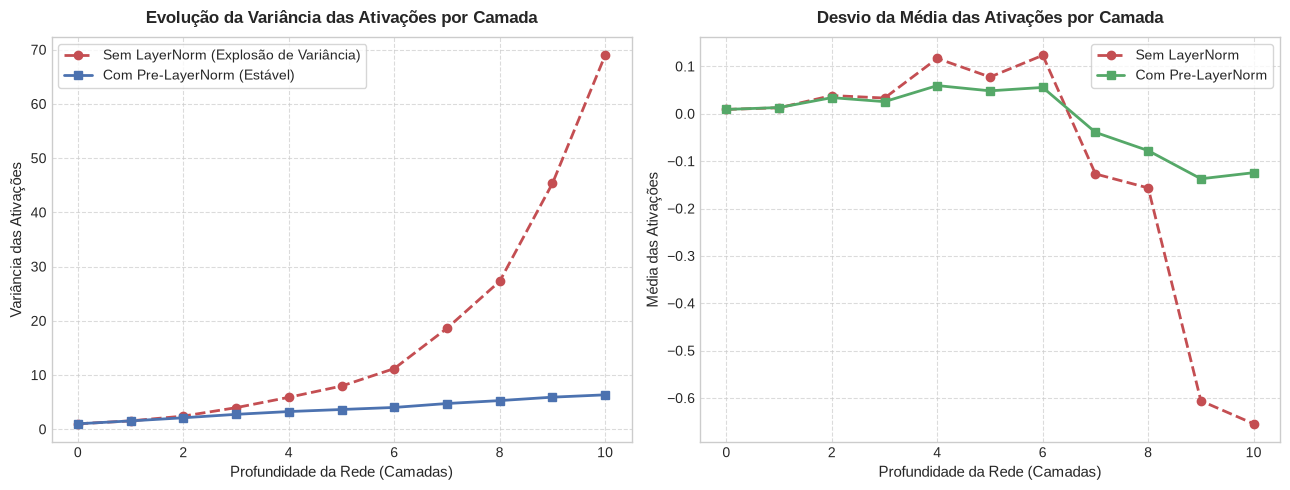

Figura salva em: /home/msoph/Documentos/0-Docs/Cursed-2026/Unoesc/IA/INTELIGENCIA-ARTIFICIAL-434302/experimentos/grafico_layernorm_sprint4.png


In [6]:
# ==============================================================================
# Experimento 4.2: Estabilidade das Ativações: Pre-LayerNorm vs Sem LayerNorm
# ==============================================================================
torch.manual_seed(42)
d_model = 128
n_camadas = 10
b_size, s_len = 8, 16

x_inicial = torch.randn(b_size, s_len, d_model)

# Com Pre-LayerNorm
x_com_ln = x_inicial.clone()
vars_com_ln = [x_com_ln.var().item()]
medias_com_ln = [x_com_ln.mean().item()]

# Sem LayerNorm
x_sem_ln = x_inicial.clone()
vars_sem_ln = [x_sem_ln.var().item()]
medias_sem_ln = [x_sem_ln.mean().item()]

for camada in range(n_camadas):
    W1 = torch.randn(d_model, d_model) / (d_model ** 0.5)
    W2 = torch.randn(d_model, d_model) / (d_model ** 0.5)
    
    # Com LN
    ln_mod = nn.LayerNorm(d_model)
    sub_ln = torch.relu(ln_mod(x_com_ln) @ W1) @ W2
    x_com_ln = x_com_ln + sub_ln
    vars_com_ln.append(x_com_ln.var().item())
    medias_com_ln.append(x_com_ln.mean().item())
    
    # Sem LN
    sub_sem_ln = torch.relu(x_sem_ln @ W1) @ W2
    x_sem_ln = x_sem_ln + sub_sem_ln
    vars_sem_ln.append(x_sem_ln.var().item())
    medias_sem_ln.append(x_sem_ln.mean().item())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
eixo_camadas = np.arange(0, n_camadas + 1)

ax1.plot(eixo_camadas, vars_sem_ln, 'o--', color='#C44E52', linewidth=2, label='Sem LayerNorm (Explosão de Variância)')
ax1.plot(eixo_camadas, vars_com_ln, 's-', color='#4C72B0', linewidth=2, label='Com Pre-LayerNorm (Estável)')
ax1.set_title('Evolução da Variância das Ativações por Camada', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Profundidade da Rede (Camadas)', fontsize=11)
ax1.set_ylabel('Variância das Ativações', fontsize=11)
ax1.legend(frameon=True, facecolor='white')
ax1.grid(True, linestyle='--', alpha=0.7)

ax2.plot(eixo_camadas, medias_sem_ln, 'o--', color='#C44E52', linewidth=2, label='Sem LayerNorm')
ax2.plot(eixo_camadas, medias_com_ln, 's-', color='#55A868', linewidth=2, label='Com Pre-LayerNorm')
ax2.set_title('Desvio da Média das Ativações por Camada', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Profundidade da Rede (Camadas)', fontsize=11)
ax2.set_ylabel('Média das Ativações', fontsize=11)
ax2.legend(frameon=True, facecolor='white')
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
caminho_fig2 = repo_root / 'experimentos' / 'grafico_layernorm_sprint4.png'
plt.savefig(caminho_fig2, dpi=300)
plt.show()
print(f"Figura salva em: {caminho_fig2}")


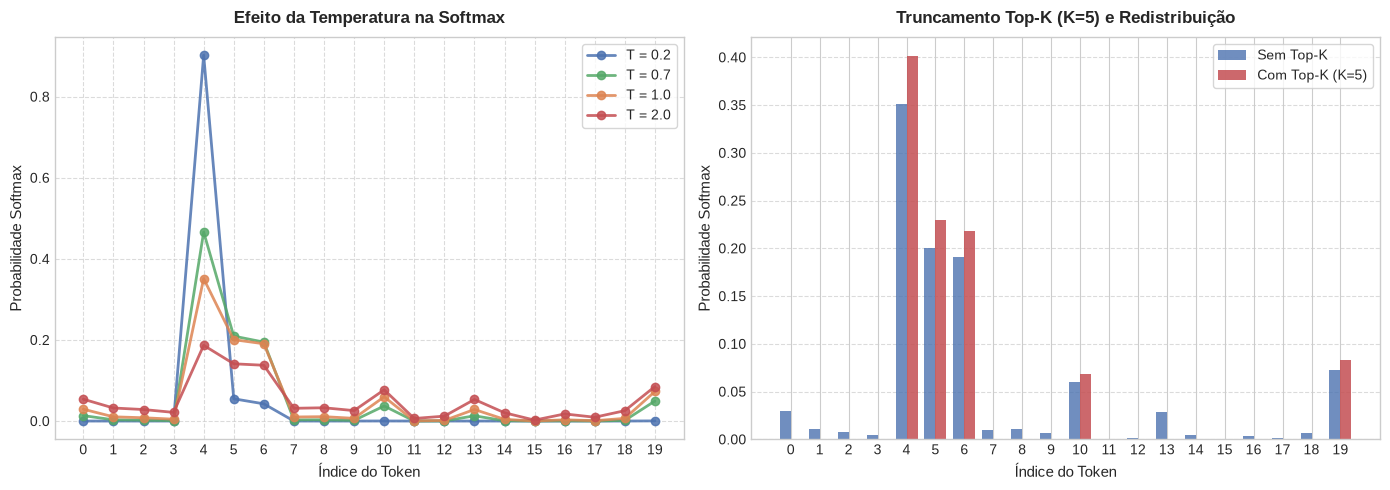

Figura salva em: /home/msoph/Documentos/0-Docs/Cursed-2026/Unoesc/IA/INTELIGENCIA-ARTIFICIAL-434302/experimentos/grafico_geracao_temp_topk.png


In [7]:
# ==============================================================================
# Experimento 4.3: Dinâmica de Amostragem (Temperatura e Top-K)
# ==============================================================================
torch.manual_seed(123)
vocab_amostra = 20
logits_brutos = torch.randn(vocab_amostra) * 2.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
tokens_indices = np.arange(vocab_amostra)

# 1. Variação de Temperatura
temps = [0.2, 0.7, 1.0, 2.0]
cores_temp = ['#4C72B0', '#55A868', '#DD8452', '#C44E52']

for temp, cor in zip(temps, cores_temp):
    escalonado = logits_brutos / temp
    dist_prob = torch.softmax(escalonado, dim=-1).numpy()
    ax1.plot(tokens_indices, dist_prob, marker='o', label=f'T = {temp}', color=cor, linewidth=2, alpha=0.85)

ax1.set_title('Efeito da Temperatura na Softmax', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Índice do Token', fontsize=11)
ax1.set_ylabel('Probabilidade Softmax', fontsize=11)
ax1.set_xticks(tokens_indices)
ax1.legend(frameon=True, facecolor='white')
ax1.grid(True, linestyle='--', alpha=0.7)

# 2. Efeito do Top-K (K=5)
k_val = 5
valores_top, _ = torch.topk(logits_brutos, k_val)
limite_min = valores_top[-1]

logits_com_topk = torch.where(logits_brutos < limite_min, torch.tensor(float('-inf')), logits_brutos)
probs_sem_filtro = torch.softmax(logits_brutos, dim=-1).numpy()
probs_com_topk = torch.softmax(logits_com_topk, dim=-1).numpy()

largura_barra = 0.38
ax2.bar(tokens_indices - largura_barra/2, probs_sem_filtro, largura_barra, label='Sem Top-K', color='#4C72B0', alpha=0.8)
ax2.bar(tokens_indices + largura_barra/2, probs_com_topk, largura_barra, label=f'Com Top-K (K={k_val})', color='#C44E52', alpha=0.85)

ax2.set_title(f'Truncamento Top-K (K={k_val}) e Redistribuição', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Índice do Token', fontsize=11)
ax2.set_ylabel('Probabilidade Softmax', fontsize=11)
ax2.set_xticks(tokens_indices)
ax2.legend(frameon=True, facecolor='white')
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
caminho_fig3 = repo_root / 'experimentos' / 'grafico_geracao_temp_topk.png'
plt.savefig(caminho_fig3, dpi=300)
plt.show()
print(f"Figura salva em: {caminho_fig3}")


## 5. Discussão Técnica e Conclusões da Sprint 4

### 1. Papel dos Componentes Estruturais
* **Pre-LayerNorm:** A normalização aplicada antes da atenção e da rede FeedForward assegura que as ativações mantenham média e variância estáveis ao longo de redes com dezenas de camadas. O experimento empírico demonstrou que sem LayerNorm a variância cresce exponencialmente, inviabilizando o treinamento.
* **Conexões Residuais:** Criam canais diretos para o fluxo de gradientes durante o *backpropagation*, mitigando o desaparecimento de gradiente e preservando a informação de entrada original.
* **Rede FeedForward (FFN):** Com a expansão para $4 \times d_{model}$ e ativação GELU, o módulo FFN desempenha papel de armazenamento de conhecimento conceitual e factual, transformando as representações de cada token de maneira independente da posição.

### 2. Geração Autoregressiva e Inferência
* A busca gananciosa (*Greedy*) seleciona de forma determinística o token com maior pontuação, tendendo a gerar repetições em contextos longos.
* O controle por **Temperatura** permite calibrar o compromisso entre determinismo e aleatoriedade: valores baixos ($T < 1.0$) priorizam consistência gramatical e precisão conceitual, enquanto valores mais altos ($T > 1.0$) favorecem a diversidade léxica.
* O filtro **Top-K** atua como uma barreira de segurança estocástica, descartando tokens improváveis da cauda longa e garantindo que apenas candidatos plausíveis concorram no sorteio categórico.

### 3. Síntese dos Entregáveis da Sprint 4
* ✅ **Glossário do Capítulo 4:** Arquivo `docs/glossario_cap4.md` contendo todos os 12 conceitos detalhados.
* ✅ **Módulo GPT:** Arquivo `src/modelo_gpt.py` modular e testado.
* ✅ **Caderno de Experimentos:** Arquivo `notebooks/sprint4.ipynb` com simulações, código executável e análises visuais.
* ✅ **Relatórios e Gráficos:** Documentos e imagens consolidados na pasta `experimentos/`.
